![](https://i.postimg.cc/v80PfVfM/Screenshot-2025-08-11-200651.png)

# Importing Libraries

In [1]:

import numpy as np                
import pandas as pd               # tabular data handling
import matplotlib.pyplot as plt   # plotting and visualizations

# File handling
import os                         # filesystem operations (paths, listing files)
import zipfile                    # open .zip files if dataset is zipped

# Image processing
import cv2                        # OpenCV: image I/O and transformations

# Machine learning utilities
from sklearn.model_selection import train_test_split  # split data into train/validation

# Keras (TensorFlow backend) high-level model building
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, UpSampling2D,
    Dropout, Conv2DTranspose, Input
)
from tensorflow.keras.callbacks import EarlyStopping


2025-09-21 06:50:08.133286: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1758437408.374919      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1758437408.440583      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# Extracting datasets

In [2]:
# Extracting datasets from .zip archives

# Paths to the dataset location (input) and our working folder
data_dir = "/kaggle/input/denoising-dirty-documents/"
work_dir = "/kaggle/working/"

# Helper function to unzip any file into the working directory
def unzip_file(zip_filename, destination):
    """
    Extracts the contents of a zip file into the specified folder.
    
    Parameters:
        zip_filename (str): Path to the .zip file
        destination (str): Folder where contents will be extracted
    """
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(destination)

# Unzip all required archives
unzip_file(os.path.join(data_dir, "train.zip"), work_dir)
unzip_file(os.path.join(data_dir, "test.zip"), work_dir)
unzip_file(os.path.join(data_dir, "train_cleaned.zip"), work_dir)
unzip_file(os.path.join(data_dir, "sampleSubmission.csv.zip"), work_dir)


In [4]:
train_images = sorted(os.listdir(os.path.join(work_dir, "train")))
clean_images = sorted(os.listdir(os.path.join(work_dir, "train_cleaned")))
test_images  = sorted(os.listdir(os.path.join(work_dir, "test")))

print(len(train_images), len(clean_images), len(test_images))


144 144 72


# Load & Preprocess an image

In [5]:
def load_image(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)   # load in grayscale directly
    img = cv2.resize(img, (540, 420)).astype("float32") / 255.0  # resize & normalize
    return img.reshape(420, 540, 1)                # add channel dimension


# Preprocessing

In [6]:
# Preprocess all images into NumPy-ready format

# Process noisy training images
train = [load_image(os.path.join(work_dir, "train", fname)) for fname in train_images]

# Process cleaned training images
train_cleaned = [load_image(os.path.join(work_dir, "train_cleaned", fname))for fname in clean_images]

# Process test images
test = [load_image(os.path.join(work_dir, "test", fname)) for fname in test_images]


# Sample Noisy vs. Cleaned image pairs

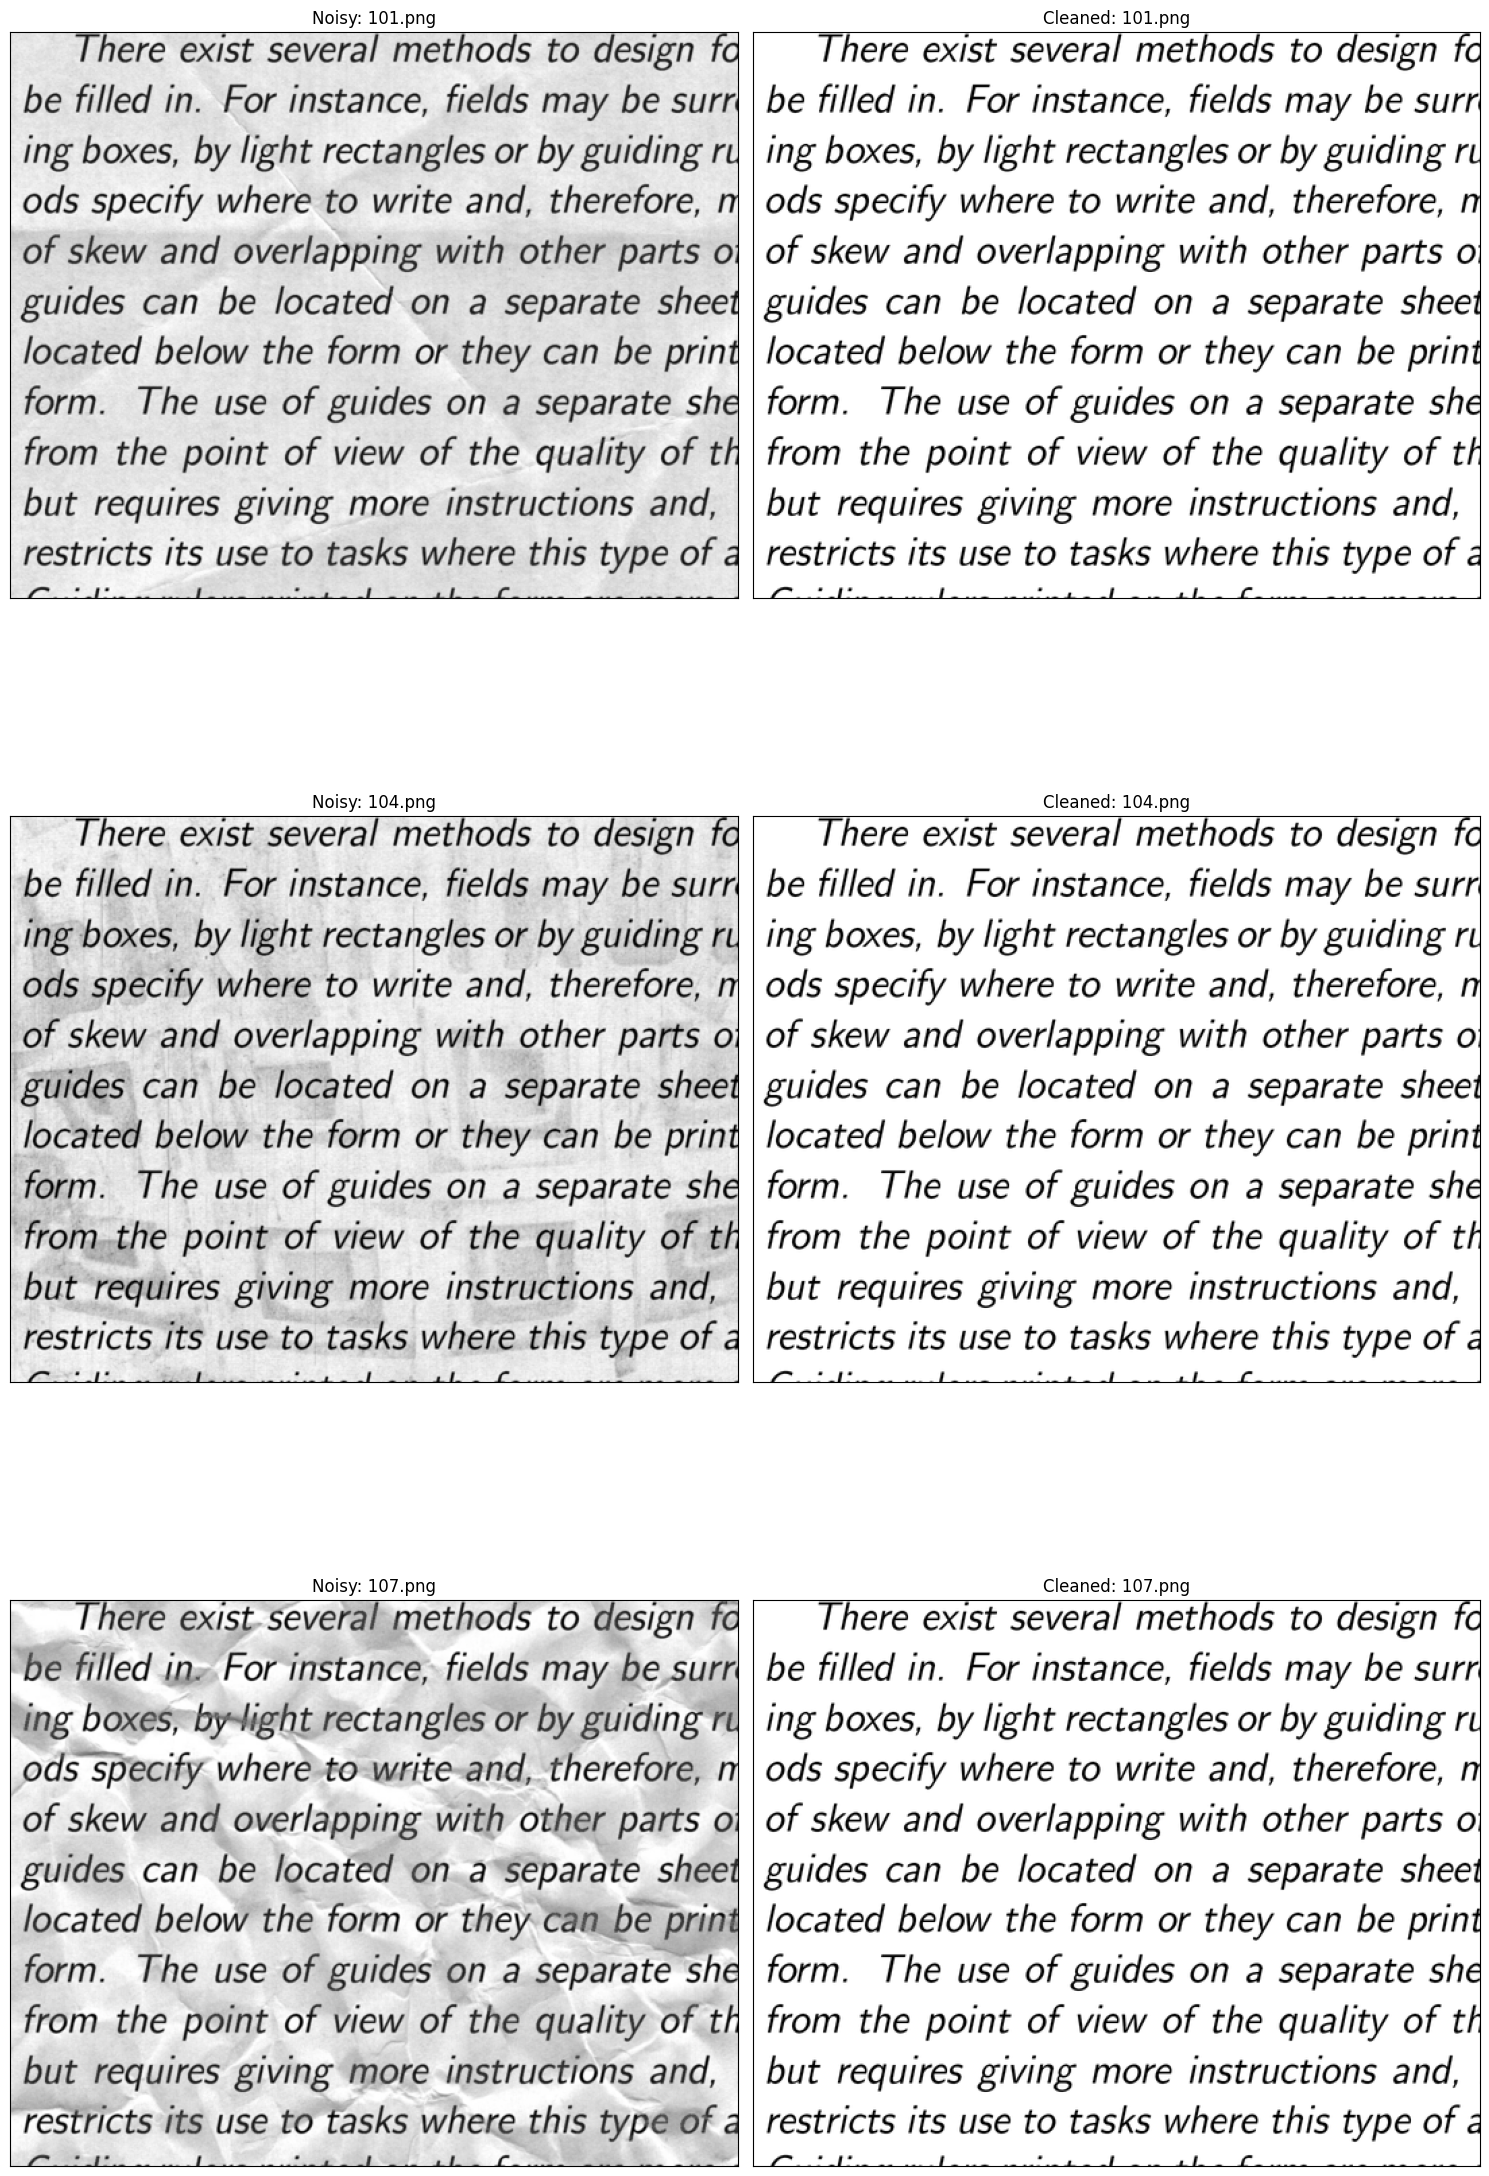

In [7]:
# sample noisy vs. cleaned image pairs
plt.figure(figsize=(15, 25))

for i in range(0, 6, 2):
    # Noisy image
    plt.subplot(3, 2, i + 1)
    plt.imshow(train[i][:, :, 0], cmap='gray')
    plt.title(f"Noisy: {train_images[i]}")
    plt.xticks([]); plt.yticks([])

    # Cleaned image
    plt.subplot(3, 2, i + 2)
    plt.imshow(train_cleaned[i][:, :, 0], cmap='gray')
    plt.title(f"Cleaned: {train_images[i]}")
    plt.xticks([]); plt.yticks([])

plt.tight_layout()
plt.show()


# Train-Test-Split

In [8]:
# Convert lists to NumPy arrays and create train/validation split
X_train = np.array(train, dtype="float32")
y_train = np.array(train_cleaned, dtype="float32")
X_test  = np.array(test, dtype="float32")

# Split data: 85% training, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)


# Model Architecture

In [9]:

c_autoencoder = Sequential()

# Encoder
# Input: (420, 540, 1)
c_autoencoder.add(
    Conv2D(filters=32, kernel_size=(3,3), activation='relu', padding='same', input_shape=(420, 540, 1)))
# Output shape after Conv2D (padding='same', stride=1):
# (420, 540, 32) — spatial dims unchanged, channels = 32

c_autoencoder.add(
    MaxPooling2D(pool_size=(2, 2), padding='same'))
# Output shape after MaxPooling2D (pool=2x2, padding='same'):
# (ceil(420/2), ceil(540/2), 32) = (210, 270, 32)

c_autoencoder.add(
    Conv2D(filters=16, kernel_size=(3,3), activation='relu', padding='same'))
# Output shape after Conv2D:
# (210, 270, 16)

c_autoencoder.add(
    MaxPooling2D(pool_size=(2, 2), padding='same'))
# Output shape after MaxPooling2D:
# (ceil(210/2), ceil(270/2), 16) = (105, 135, 16)


# Decoder
c_autoencoder.add(
    Conv2DTranspose(filters=8, kernel_size=3, strides=2, activation='relu', padding='same'))
# Output shape after Conv2DTranspose (stride=2, padding='same'):
# approximately doubles spatial dims
# (105*2, 135*2, 8) = (210, 270, 8)

c_autoencoder.add(
    Conv2DTranspose(filters=16, kernel_size=3, strides=2, activation='relu', padding='same'))
# Output shape:
# (210*2, 270*2, 16) = (420, 540, 16)


# Output layer
c_autoencoder.add(
    Conv2D(filters=1, kernel_size=(3,3), activation='sigmoid', padding='same'))
# Output shape after final Conv2D:
# (420, 540, 1) — matches original input size

c_autoencoder.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1758438509.121958      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 420, 540, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 210, 270, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 210, 270, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 105, 135, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 210, 270, 8)    │         1,160 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 420, 540, 16)   │         1,168 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 420, 540, 1)    │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,417 (28.97 KB)

 Trainable params: 7,417 (28.97 KB)

 Non-trainable params: 0 (0.00 B)

# Compile and train the autoencoder


In [10]:
# Compile and train the autoencoder

# Compile the model
c_autoencoder.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']  # Mean Absolute Error
)

# Early stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor='loss',           # watch the training loss
    patience=10,               # stop if no improvement for 10 epochs
    restore_best_weights=True  # revert to the best model
)

# Train the model
history = c_autoencoder.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/200


I0000 00:00:1758438782.853655     106 service.cc:148] XLA service 0x78cf58088090 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1758438782.856352     106 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1758438783.203468     106 cuda_dnn.cc:529] Loaded cuDNN version 90300


3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.2214 - mae: 0.4562

I0000 00:00:1758438790.050274     106 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 938ms/step - loss: 0.2202 - mae: 0.4550 - val_loss: 0.2162 - val_mae: 0.4516
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.2116 - mae: 0.4462 - val_loss: 0.2013 - val_mae: 0.4360
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.1920 - mae: 0.4253 - val_loss: 0.1592 - val_mae: 0.3867
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - loss: 0.1395 - mae: 0.3578 - val_loss: 0.0878 - val_mae: 0.2564
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.0761 - mae: 0.2159 - val_loss: 0.0765 - val_mae: 0.1450
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - loss: 0.0734 - mae: 0.1342 - val_loss: 0.0802 - val_mae: 0.1282
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.0745 - mae: 0.1232 - val_loss: 0.0788 - val_mae: 0.1324
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - loss: 0.0712 - mae: 0.1300 - val_loss: 0.0748 - val_mae: 0.1518
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.0673 - mae: 0.1526 - v

# Plotting Loss

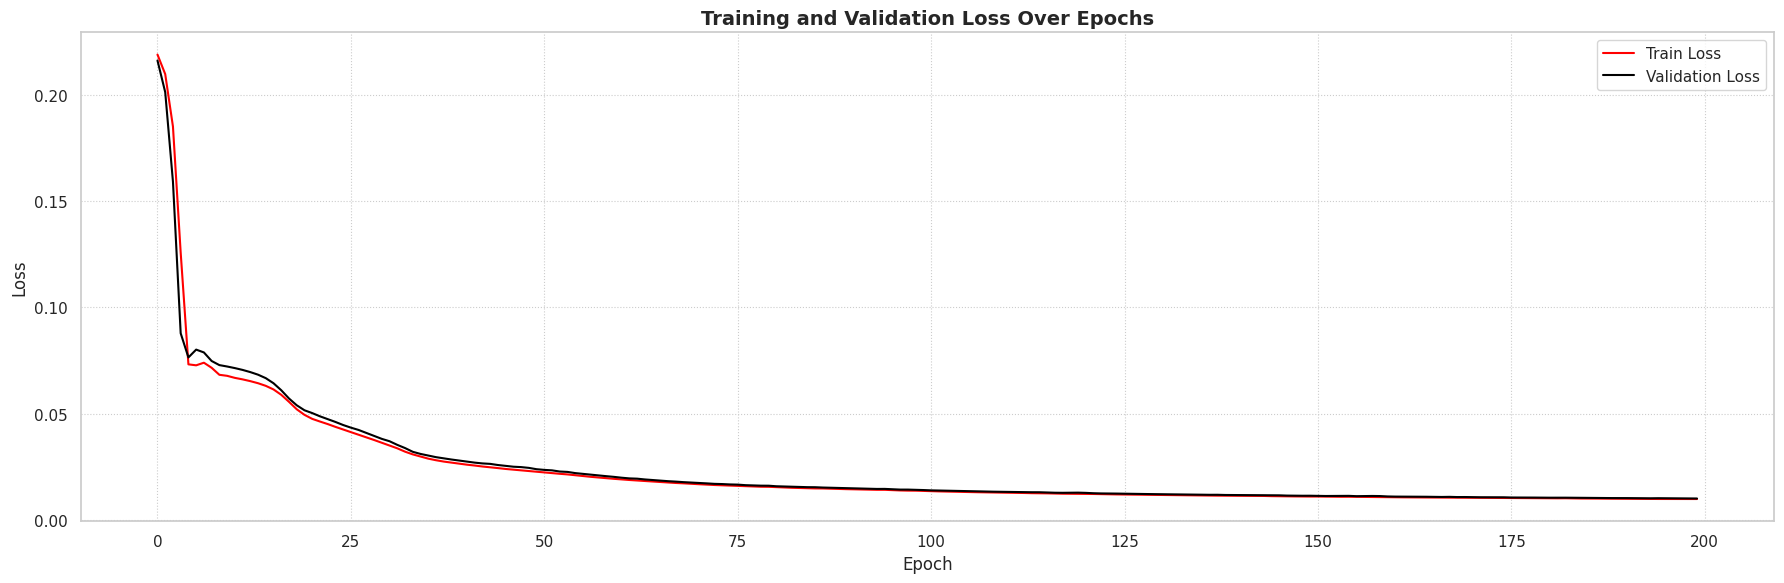

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

epoch_loss = history.history['loss']
epoch_val_loss = history.history['val_loss']


plt.figure(figsize=(18,6))

# Loss plot
plt.plot(epoch_loss, label='Train Loss', color='red')
plt.plot(epoch_val_loss, label='Validation Loss', color='black')
plt.title('Training and Validation Loss Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle=':', linewidth=0.8)

plt.tight_layout()
plt.show()


# Prediction on Test Images

In [12]:
y_pred = c_autoencoder.predict(X_test, batch_size=16)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 290ms/step


# Plotting The Results

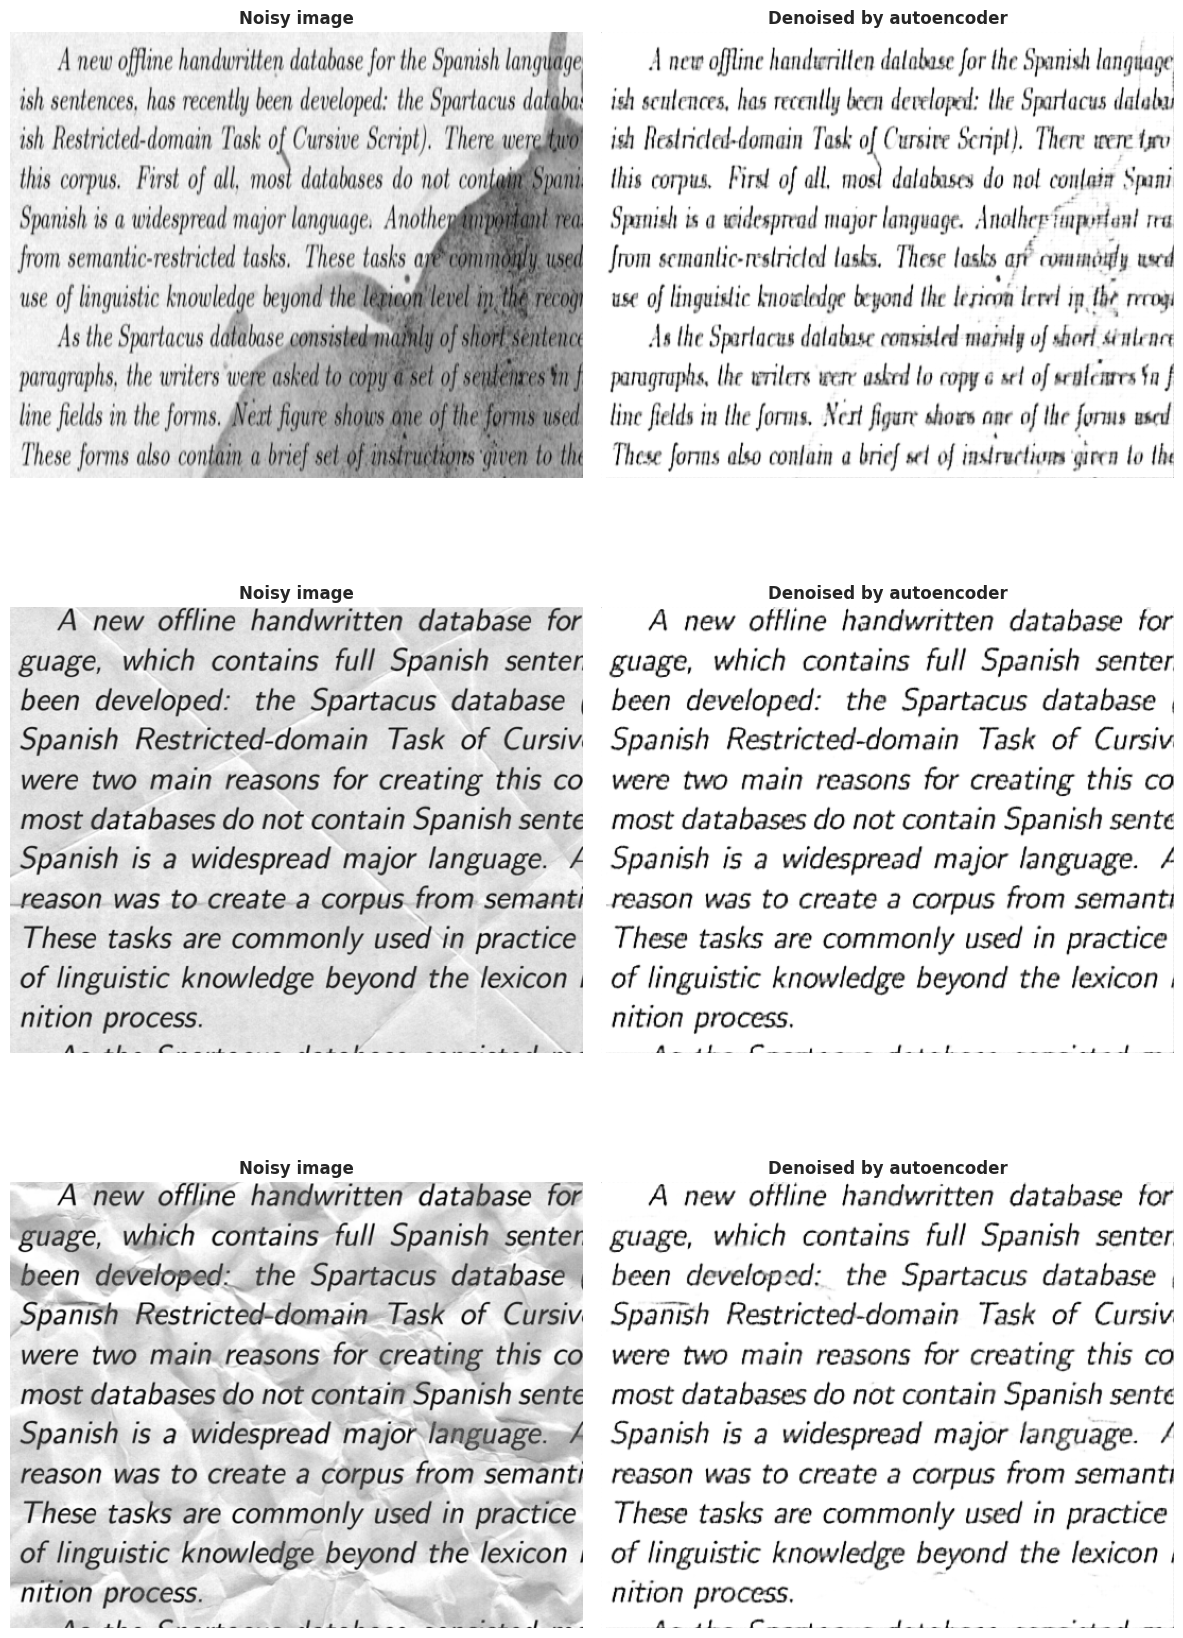

In [13]:
import seaborn as sns
sns.set(style='whitegrid')

plt.figure(figsize=(12, 18))

for i in range(0, 6, 2):
    # Noisy Image subplot
    plt.subplot(3, 2, i + 1)
    plt.imshow(X_test[i][:, :, 0], cmap='gray')
    plt.title("Noisy image", fontsize=12, fontweight='bold')
    plt.axis('off')

    # Denoised Image subplot
    plt.subplot(3, 2, i + 2)
    plt.imshow(y_pred[i][:, :, 0], cmap='gray')
    plt.title("Denoised by autoencoder", fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()


<span style="color: white; background-color: red; padding: 10px 20px; border-radius: 10px; font-size: 36px; font-weight: bold;">Smash That Upvote !! Thanks ! 🚀😃</span>
